In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import scienceplots
from network_creation.stats.er_payoff import expected_aggregate_payoff

plt.style.use("science")

In [2]:
def get_star_payoff(N, v_k, delta):
    normalization = float(N * (2 * N - 1))
    pair_count = float(N - 1)
    return (
        v_k
        * (
            float(N)
            + 2.0 * pair_count * delta
            + pair_count * float(N - 2) * delta**2
        )
        + pair_count**2
    ) / normalization

def get_empty_payoff(N, v_k, delta):
    return (v_k+(N-1)) / (2 * N - 1)

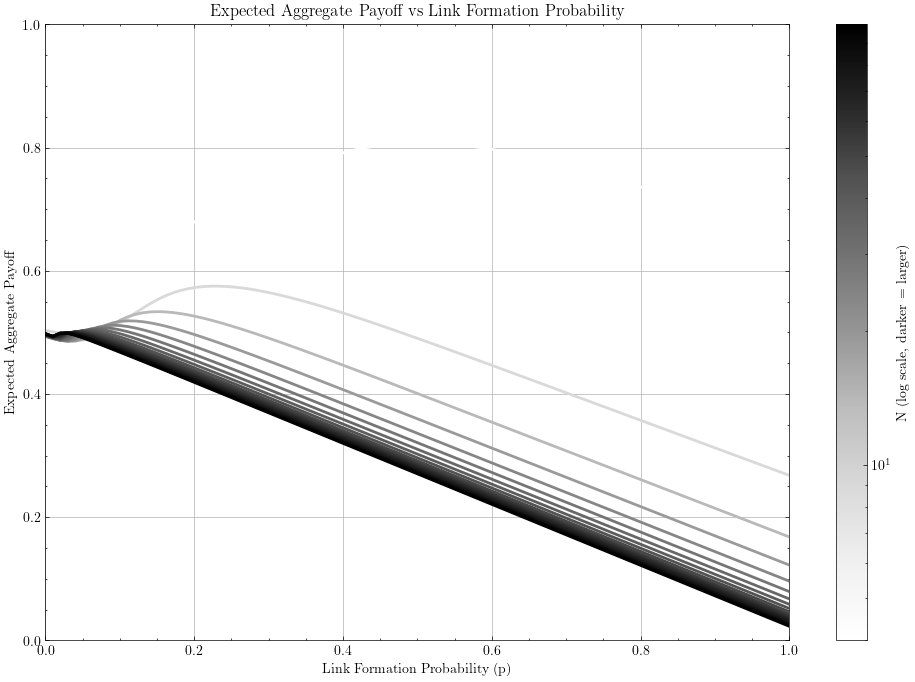

In [3]:
N_values = np.arange(4, 100, 5, dtype=int)
p_values = np.linspace(0, 1, 100, dtype=float)

results = np.zeros((len(N_values), len(p_values)))
for i, N in enumerate(N_values):
    for j, p in enumerate(p_values):
        results[i, j] = expected_aggregate_payoff(N=N, v_k=10/(2*N), p=p, delta=0.9, epsilon=1e-9)

fig, ax = plt.subplots(figsize=(12, 8))

norm = LogNorm(vmin=N_values.min(), vmax=N_values.max())
cmap = plt.cm.Greys

for i, N in enumerate(N_values):
    ax.plot(p_values, results[i], color=cmap(norm(N)), linewidth=2)

ax.set_title("Expected Aggregate Payoff vs Link Formation Probability")
ax.set_xlabel("Link Formation Probability (p)")
ax.set_ylabel("Expected Aggregate Payoff")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(True)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, label="N (log scale, darker = larger)")

plt.show()

In [4]:
v_k = np.linspace(0.001, 0.999, 100)
delta = np.linspace(0.001, 0.999, 100)

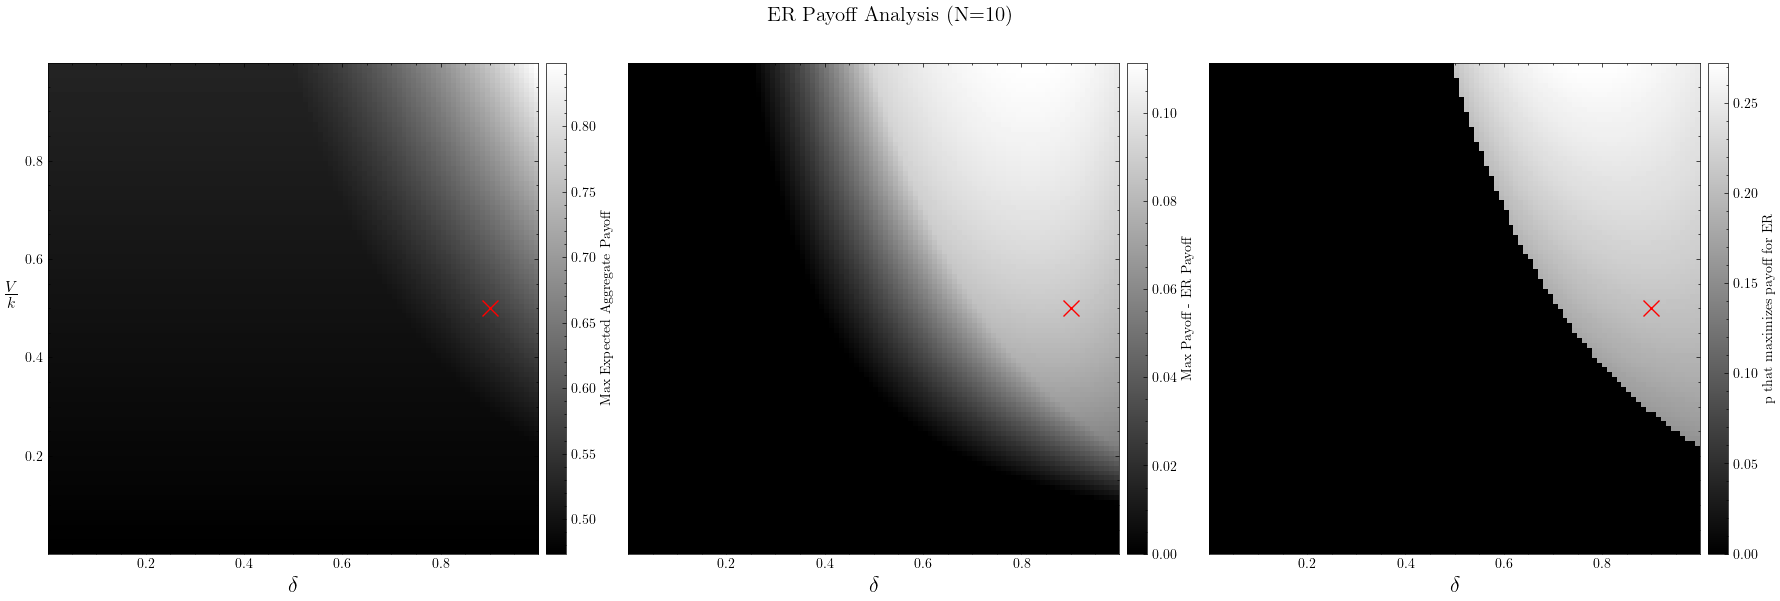

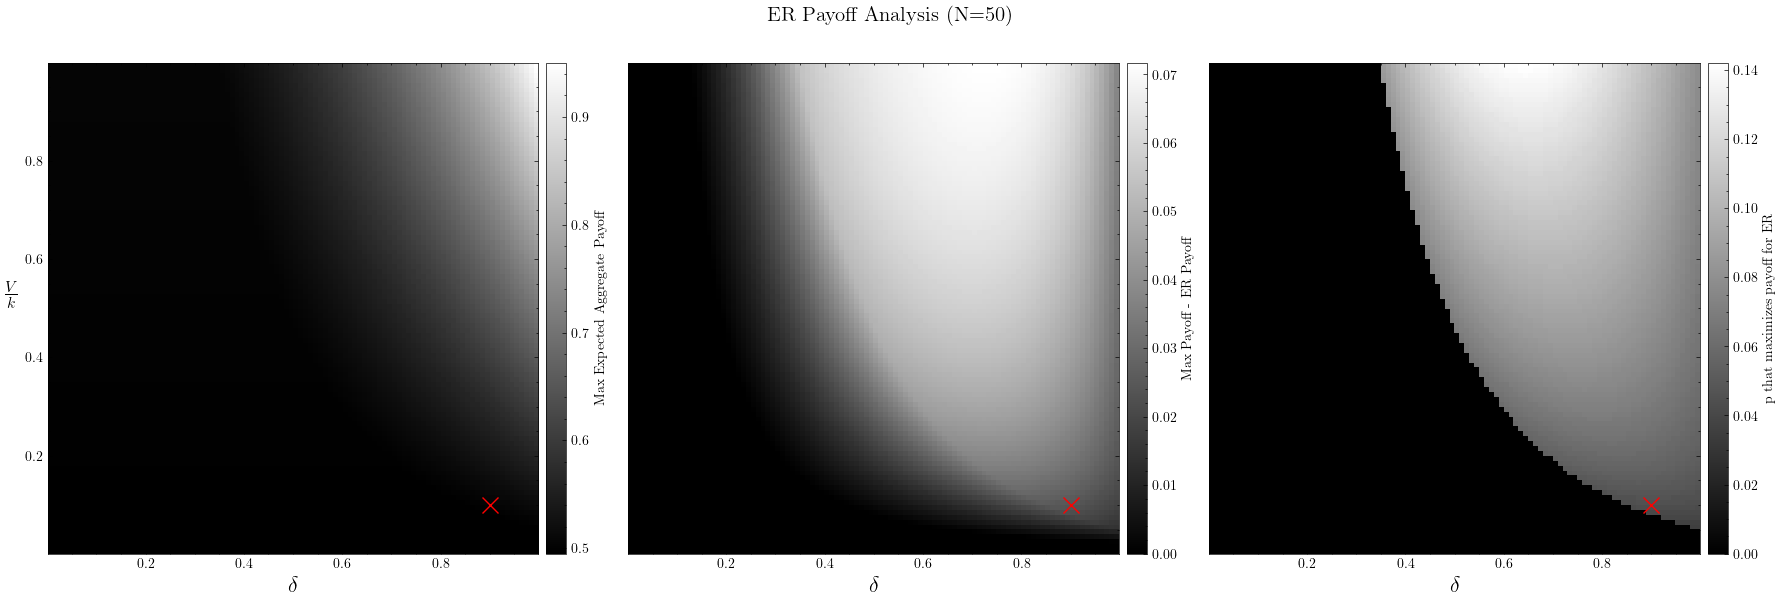

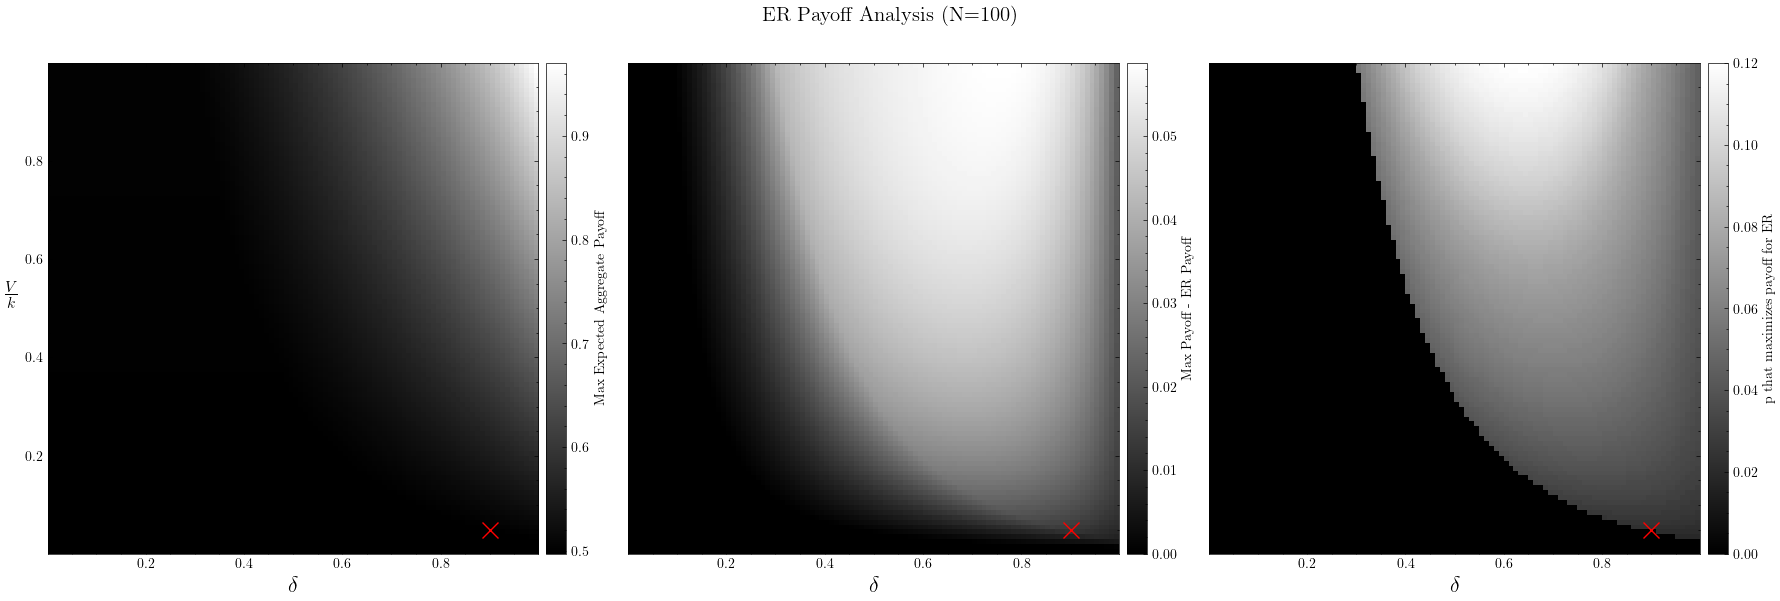

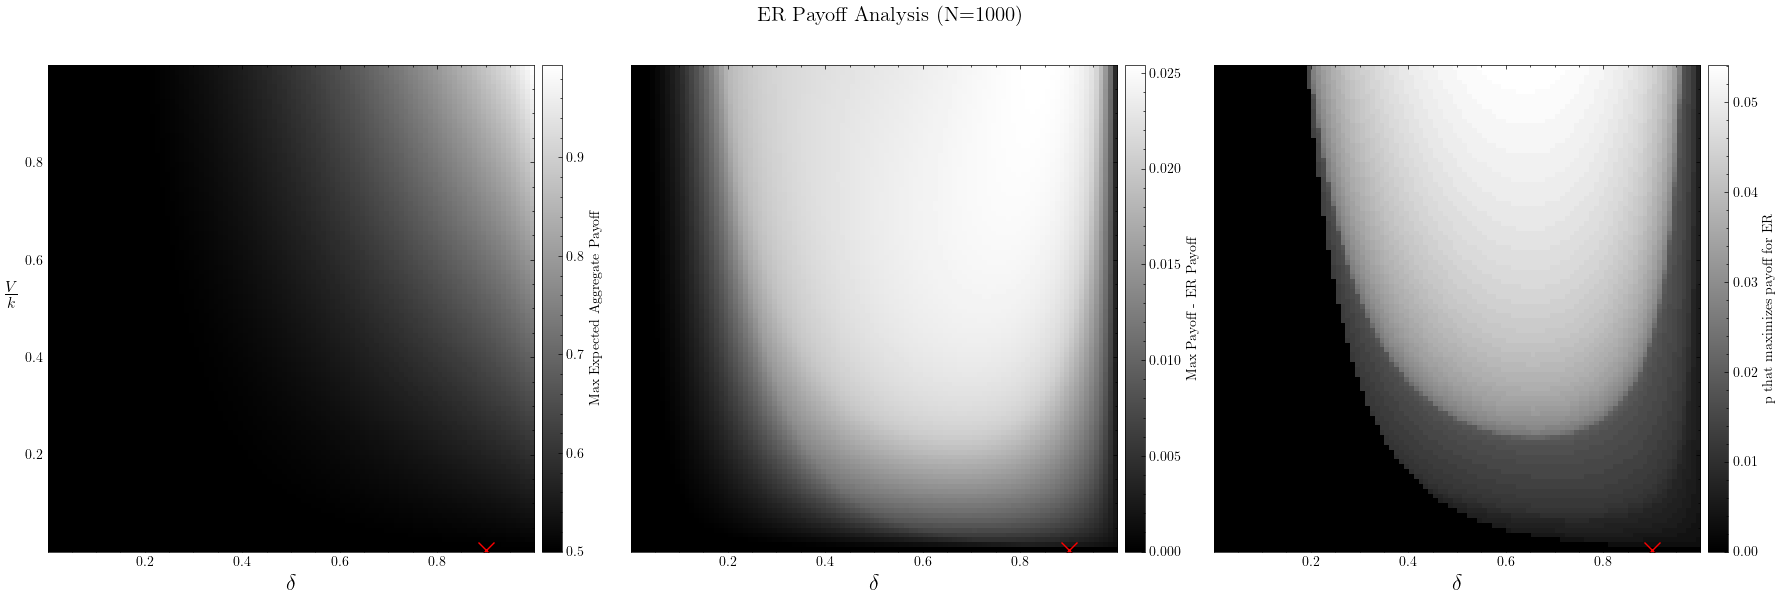

In [5]:
for N in [10, 50, 100, 1000]:
    er_results = np.array(
        [[expected_aggregate_payoff(N, v, None, d, epsilon=1e-9) for d in delta] for v in v_k],
        dtype=float,
    )
    er_max_payoff = er_results[..., 0]
    er_p = er_results[..., 1]

    max_payoff = np.array(
        [[max(get_star_payoff(N=N, v_k=v, delta=d), get_empty_payoff(N=N, v_k=v, delta=d)) for d in delta] for v in v_k],
        dtype=float,
    )

    fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(6*3, 6), sharex=True, sharey=True)

    im0 = ax[0].imshow(
        er_max_payoff,
        origin="lower",
        aspect="equal",
        extent=(delta.min(), delta.max(), v_k.min(), v_k.max()),
        cmap="gray",
    )
    ax[0].set_box_aspect(1)
    div0 = make_axes_locatable(ax[0])
    cax0 = div0.append_axes("right", size="4%", pad=0.08)
    fig.colorbar(im0, cax=cax0, label="Max Expected Aggregate Payoff")
    ax[0].set_xlabel(r"$\delta$", size=16)
    ax[0].set_ylabel(r"$\frac{V}{k}$", size=16, rotation=0, labelpad=10)
    ax[0].plot(0.9, 10 / (2 * N), "x", color="red", markersize=12)


    im0 = ax[1].imshow(
        max_payoff-er_max_payoff,
        origin="lower",
        aspect="equal",
        extent=(delta.min(), delta.max(), v_k.min(), v_k.max()),
        cmap="gray",
    )
    ax[1].set_box_aspect(1)
    div0 = make_axes_locatable(ax[1])
    cax0 = div0.append_axes("right", size="4%", pad=0.08)
    fig.colorbar(im0, cax=cax0, label="Max Payoff - ER Payoff")
    ax[1].set_xlabel(r"$\delta$", size=16)
    ax[1].plot(0.9, 10 / (2 * N), "x", color="red", markersize=12)

    im1 = ax[2].imshow(
        er_p,
        origin="lower",
        aspect="equal",
        extent=(delta.min(), delta.max(), v_k.min(), v_k.max()),
        cmap="gray",
    )
    ax[2].set_box_aspect(1)
    div1 = make_axes_locatable(ax[2])
    cax1 = div1.append_axes("right", size="4%", pad=0.08)
    fig.colorbar(im1, cax=cax1, label="p that maximizes payoff for ER")
    ax[2].set_xlabel(r"$\delta$", size=16)
    ax[2].plot(0.9, 10 / (2 * N), "x", color="red", markersize=12)


    fig.suptitle(f"ER Payoff Analysis (N={N})", size=15)
    plt.tight_layout()
    plt.show()